# Lecture 1: Introduction and the Python Quantum-Computing Toolkit

[Course contents](../00_course_contents.md) | [← Previous lecture](./00_why_quantum_engineering.ipynb) | [Next lecture →](./02_linear_algebra.ipynb) | [Supplementary lecture](./13_quantum_technology_roadmaps_and_ai.ipynb)

> **Open course material.** This notebook may be downloaded, taught, adapted, and shared with attribution. It supports institutional teaching, independent study, examination review, and preparation for quantum-technology roles. See the [reuse terms](../LICENSE), [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and [citation metadata](../CITATION.cff).

## Learning objectives

- Explain the roles of numerical, symbolic, circuit, and open-system tools.
- Write and execute reproducible Python calculations in a Jupyter notebook.
- Represent a normalized qubit state, calculate measurement probabilities, and build a simple Qiskit circuit.

## Core ideas

- **Choose the right representation.** Arrays, symbolic expressions, circuits, and density operators answer different questions.
- **Classical simulation still scales exponentially.** A generic $n$-qubit statevector stores $2^n$ complex amplitudes.
- **Reproducibility is part of the result.** Record versions, restart the kernel, and run from top to bottom before sharing a notebook.


## Software environment

The course uses the pinned packages in [`requirements.txt`](../requirements.txt). If they are not installed in the active Jupyter kernel, run:

```python
%pip install -r ../requirements.txt
```

Restart the kernel after installation. The next cell contains every library import required by this lecture; the notebook does not depend on variables or imports created by another lecture.

In [1]:
# Complete imports for this lecture.
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from sympy.physics.quantum import Bra, Ket
import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import qutip
from qutip import basis
import scienceplots

## A computational workflow for quantum science

Python connects several complementary layers of a quantum-computing workflow:

- **NumPy and SciPy** provide numerical arrays, linear algebra, optimization, and differential-equation solvers.
- **SymPy** keeps algebraic expressions exact and is useful for derivations.
- **Qiskit** represents, transforms, simulates, and executes gate-based quantum circuits.
- **QuTiP** focuses on quantum dynamics, including open-system master equations.
- **Matplotlib** visualizes data and simulation results.

A classical state-vector simulator stores $2^n$ complex amplitudes for $n$ qubits, so its memory requirement grows exponentially. Simulation is therefore a model of a quantum computation, not evidence that the same calculation will scale efficiently on a classical computer or run without noise on hardware.


In [2]:
# Slicing

numbers = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

sliced_numbers = numbers[2:5]

sliced_numbers

[2, 3, 4]

In [3]:
# Exchange the values of variables

a = 10
b = 5

a, b = b, a

print('a =', a)
print('b =', b)

a = 5
b = 10


## The Jupyter execution model

A notebook combines executable cells, mathematical notation, prose, and figures. All code cells share one live Python kernel: definitions remain in memory until the kernel is restarted. Consequently, execution order matters. Before sharing a result, restart the kernel and run the notebook from top to bottom; this detects hidden dependencies on stale variables.


### Useful Jupyter shortcuts

In command mode (`Esc`), `A` inserts a cell above, `B` inserts one below, `D,D` deletes a selected cell, `Z` restores a deleted cell, and `Shift-M` merges selected cells. `Shift-Enter` executes a cell. `Ctrl+/` toggles comments in a code cell. Shortcut availability can vary slightly between Jupyter Notebook and JupyterLab.


### Markdown for a scientific narrative


Markdown supports *italic text*, **bold text**, headings, links, lists, code, tables, and LaTeX mathematics. Use prose to state assumptions and interpret a result rather than leaving a sequence of unexplained code cells.


Examples of inline notation include $x^2$, $a_k$, and $|\psi\rangle$. A Markdown list can organize the main objects in a calculation:

- states,
- operators,
- measurements.


Figures can be embedded in a notebook, while externally hosted videos can be linked. Remote media require a network connection.


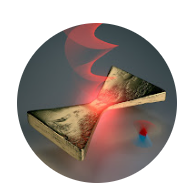

*The conceptual illustration evokes controlled light–matter interaction; it is not a circuit diagram or a measured data set.*


[Watch the introductory quantum-computing video on YouTube](https://www.youtube.com/watch?v=bd8Yp6cinfU).


**Displayed mathematical expressions**

$$
\int_x^y t^2\,dt,\qquad
\frac{1}{2},\qquad
\sqrt{x},\qquad
\sum_{k=0}^{n-1} a_k,\qquad
\sin^2 x+\cos^2 x=1.
$$


**Common quantum notation**

$$
\varepsilon,\qquad
\hat{A},\qquad
A^\dagger,\qquad
\overline{x+y},\qquad
\langle\phi|\psi\rangle,\qquad
|\psi\rangle\langle\psi|.
$$


## Scientific Python imports


The conventional aliases are `plt` for Matplotlib, `np` for NumPy, and `sp` for SymPy. Prefixing names makes the library responsible for an operation explicit.


NumPy's central object is the multidimensional `ndarray`. Quantum state vectors and operators should normally use `dtype=complex`, even when their initial entries happen to be real. The `@` operator performs matrix multiplication; `*` performs element-wise multiplication.


In [4]:
Z = np.array([[1, 0], [0, -1]], dtype=complex)
identity = np.eye(2, dtype=complex)

print(identity + Z)

[[2.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]


## Quantum states as complex arrays

In a chosen orthonormal basis, a pure state is a complex column vector

$$
|\psi\rangle=\begin{bmatrix}\alpha\\\beta\end{bmatrix},
\qquad |\alpha|^2+|\beta|^2=1.
$$

The normalization condition is $\langle\psi|\psi\rangle=1$. Measuring in the computational basis gives outcome probabilities $p(0)=|\alpha|^2$ and $p(1)=|\beta|^2$. NumPy's `vdot` conjugates its first argument, so it implements the complex inner product.


In [5]:
psi = np.array([1, 1j], dtype=complex)
psi = psi / np.linalg.norm(psi)

norm_squared = np.vdot(psi, psi).real
probabilities = np.abs(psi) ** 2

print("state:", psi)
print("norm squared:", norm_squared)
print("P(0), P(1):", probabilities)
print("probability sum:", probabilities.sum())

state: [0.70710678+0.j         0.        +0.70710678j]
norm squared: 0.9999999999999998
P(0), P(1): [0.5 0.5]
probability sum: 0.9999999999999998


SymPy represents exact symbolic expressions. This is useful when a result such as `sqrt(2)` should remain exact rather than being rounded to a floating-point approximation.


In [6]:
x = sp.symbols('x')
x**2

x**2

In [7]:
exact_value = sp.sin(x).subs(x, 1)
exact_value, sp.N(exact_value, 10)

(sin(1), 0.8414709848)

In [8]:
ket_1 = Ket(r"\psi_1")
ket_2 = Ket(r"\psi_2")
bra = Bra(r"\psi")

ket_1, ket_2, bra

(|\psi_1>, |\psi_2>, <\psi|)

In [9]:
state = (ket_1 + ket_2) / sp.sqrt(2)
state

sqrt(2)*(|\psi_1> + |\psi_2>)/2

In [10]:
a, b, c, d = sp.symbols('a b c d')

matrix = sp.Matrix([[a, b],
                   [c, d]])
matrix

Matrix([
[a, b],
[c, d]])

## Exact algebra, floating point, and numerical checks

Symbolic equality and floating-point closeness answer different questions. SymPy can prove an identity exactly. Numerical libraries round results, so tests should use a tolerance:

$$
a\approx b
\quad\Longleftrightarrow\quad
|a-b|\leq \mathrm{atol}+\mathrm{rtol}|b|.
$$

For quantum states, normalization should be checked with <code>np.isclose</code>, and operator identities such as $U^\dagger U=I$ with <code>np.allclose</code>. Two normalized state vectors related by a unit-modulus factor $e^{i\gamma}$, with $\gamma\in\mathbb R$, represent the same pure state even though their arrays are not element-wise equal.


In [11]:
theta = np.pi / 7
global_phase = np.exp(1j * theta)
same_physical_state = global_phase * psi

print("arrays equal:", np.allclose(psi, same_physical_state))
print("overlap magnitude:", abs(np.vdot(psi, same_physical_state)))
print("normalized:", np.isclose(np.vdot(psi, psi).real, 1.0))

arrays equal: False
overlap magnitude: 0.9999999999999999
normalized: True


## Installing the course environment

Create a virtual environment and install the versioned dependencies from a terminal:

```bash
python -m venv .venv
# Windows: .venv\Scripts\activate
# macOS/Linux: source .venv/bin/activate
python -m pip install -r requirements.txt
```

Inside a notebook, `%pip` installs into the active kernel environment, but a project-level requirements file is easier to reproduce. Avoid mixing a pre-1.0 Qiskit installation with Qiskit 2.x packages.


In [12]:
print("Qiskit version:", qiskit.__version__)

Qiskit version: 2.5.2


In [13]:
QuantumCircuit(1).draw()

q:

## A current Qiskit state-vector workflow

A `QuantumCircuit` records operations; it does not itself store the resulting amplitudes. For an ideal circuit without measurement, `Statevector.from_instruction` calculates

$$
|\psi_{\mathrm{out}}\rangle=U|\psi_{\mathrm{in}}\rangle.
$$

The following circuit prepares $H|0\rangle=(|0\rangle+|1\rangle)/\sqrt2$. Exact probabilities are properties of the state vector; finite-shot counts are random estimates discussed below.


In [14]:
plus_circuit = QuantumCircuit(1)
plus_circuit.h(0)

plus_state = Statevector.from_instruction(plus_circuit)
print(plus_state)
print(plus_state.probabilities_dict())
plus_circuit.draw()

Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


┌───┐
q: ┤ H ├
   └───┘

## Domain-specific libraries

The next cells confirm that Qiskit and QuTiP are available. Qiskit supplies circuit and quantum-information objects; QuTiP supplies states, operators, solvers, and visualization tools for quantum dynamics.


In [15]:
print("QuTiP version:", qutip.__version__)

QuTiP version: 5.3.1


In [16]:
basis(2, 0)

Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
Qobj data =
[[1.]
 [0.]]

## Plotting numerical results

A useful scientific plot identifies the quantity on each axis, includes units when applicable, and uses a legend when multiple data sets would otherwise be ambiguous.


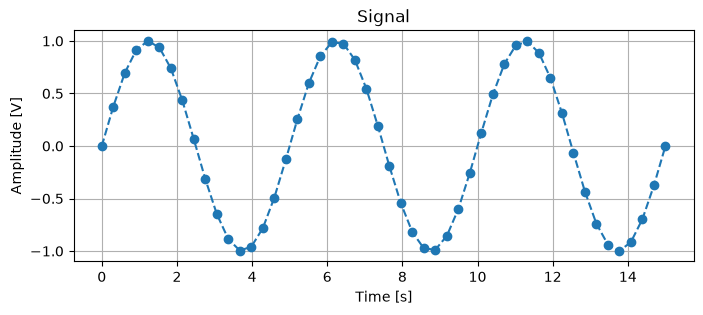

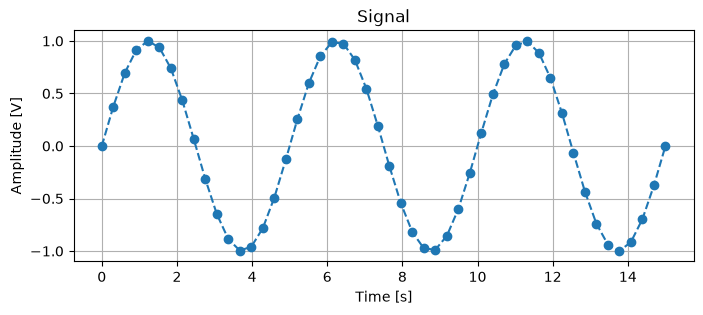

In [17]:
%matplotlib inline

time = np.linspace(0, 15, 50)
frequency_hz = 0.2
angular_frequency = 2 * np.pi * frequency_hz
signal = np.sin(angular_frequency * time)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(time, signal, 'o--')
ax.set(xlabel='Time [s]', ylabel='Amplitude [V]', title='Signal')
ax.grid(True)
fig

*The sampled sinusoid completes three cycles in 15 seconds; markers show the discrete sample locations while the line guides the eye.*


### Consistent figure styles

SciencePlots provides reusable Matplotlib style sheets. The `no-latex` style avoids a system-level TeX dependency and makes the notebook portable.


In [18]:
plt.style.use(['science', 'notebook', 'grid', 'no-latex'])

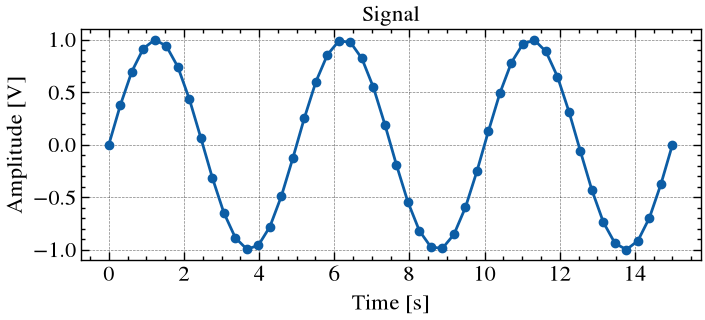

In [19]:
time = np.linspace(0, 15, 50)
frequency_hz = 0.2
angular_frequency = 2 * np.pi * frequency_hz
signal = np.sin(angular_frequency * time)

plt.figure(figsize=(8,3))

plt.plot(time, signal, 'o-')

plt.xlabel('Time [s]', fontsize=16)
plt.ylabel('Amplitude [V]', fontsize=16)
plt.title('Signal', fontsize=16)

plt.show()

*The same 0.2 Hz sinusoid is redrawn with the shared publication style, labeled time and amplitude axes, and a dimensionless sine argument $\omega t$.*


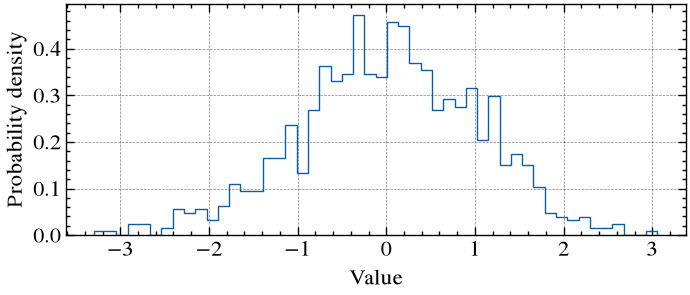

In [20]:
rng = np.random.default_rng(123)
res = rng.standard_normal(1000)

plt.figure(figsize=(8, 3))
plt.hist(res, bins=50, density=True, histtype='step')
plt.xlabel('Value')
plt.ylabel('Probability density')
plt.show()

*The step histogram is the empirical probability density of 1,000 seeded standard-normal samples, so its finite-bin outline only approximates the smooth Gaussian density.*


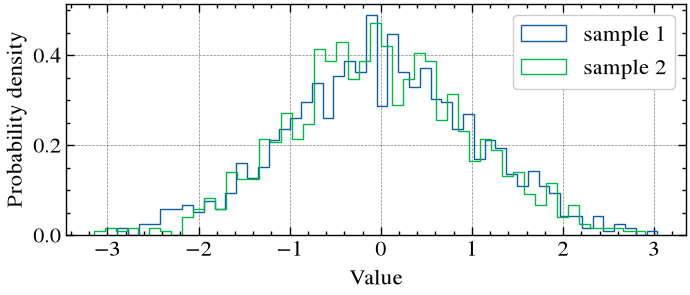

In [21]:
res1 = rng.standard_normal(1000)
res2 = rng.standard_normal(1000)

plt.figure(figsize=(8, 3))
plt.hist(res1, bins=50, density=True, histtype='step', label='sample 1')
plt.hist(res2, bins=50, density=True, histtype='step', label='sample 2')
plt.xlabel('Value')
plt.ylabel('Probability density')
plt.legend()
plt.show()

*The two overlaid step histograms come from independent standard-normal samples; their small differences illustrate finite-sample variability.*


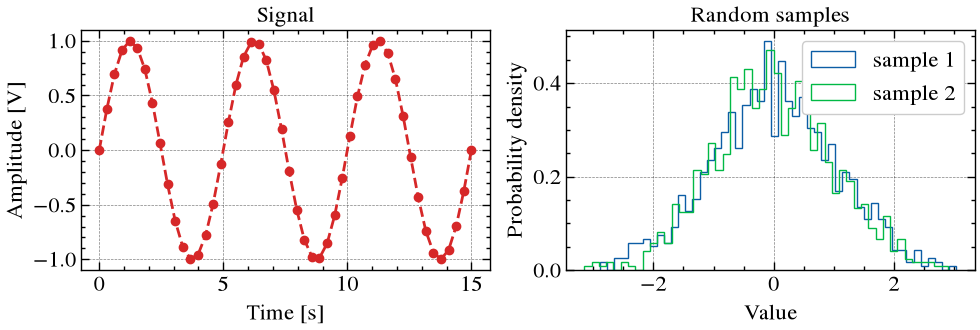

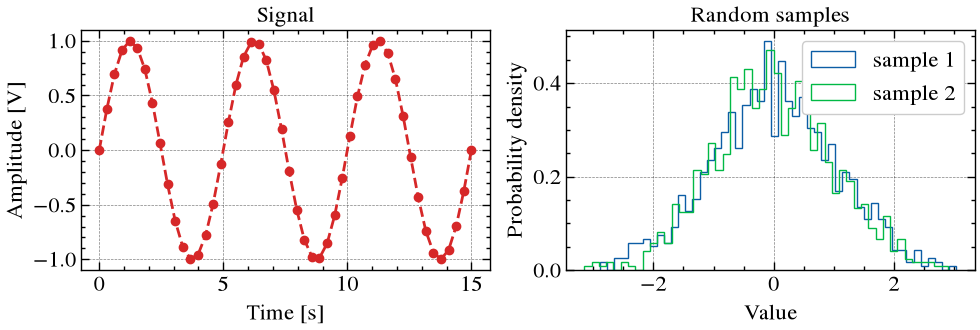

In [22]:
fig, (ax_signal, ax_hist) = plt.subplots(1, 2, figsize=(10, 3.5))

ax_signal.plot(time, signal, 'o--', color='tab:red')
ax_signal.set(xlabel='Time [s]', ylabel='Amplitude [V]', title='Signal')

ax_hist.hist(res1, bins=50, density=True, histtype='step', label='sample 1')
ax_hist.hist(res2, bins=50, density=True, histtype='step', label='sample 2')
ax_hist.set(xlabel='Value', ylabel='Probability density', title='Random samples')
ax_hist.legend()

fig.tight_layout()
fig

*The combined figure places the time-domain sinusoid beside the two empirical distributions to demonstrate consistent axes, labels, legends, and styling across panels.*


## Exact probabilities and finite-shot sampling

If an outcome has probability $p$, its observed frequency from $N$ independent shots fluctuates with standard deviation

$$
\sigma_{\hat p}=\sqrt{\frac{p(1-p)}{N}}.
$$

Increasing the shot count reduces sampling uncertainty as $1/\sqrt N$, but it does not remove device noise or model error. A fixed random-number seed makes a pedagogical simulation repeatable; hardware outcomes remain experimental data.


In [23]:
shots = 1000
sample_rng = np.random.default_rng(7)
counts = sample_rng.multinomial(shots, probabilities)
frequencies = counts / shots
standard_errors = np.sqrt(probabilities * (1 - probabilities) / shots)

print("counts:", dict(enumerate(counts)))
print("frequencies:", frequencies)
print("one-sigma sampling uncertainty:", standard_errors)

counts: {0: np.int64(500), 1: np.int64(500)}
frequencies: [0.5 0.5]
one-sigma sampling uncertainty: [0.01581139 0.01581139]


## Key takeaways

- Use **NumPy/SciPy** for numerical work, **SymPy** for exact algebra, **Qiskit** for circuits, and **QuTiP** for open-system dynamics.
- Represent quantum states with complex arrays and use conjugating inner products such as `np.vdot`.
- Distinguish exact state probabilities from finite-shot frequencies and from hardware noise.
- A notebook is reliable only when it executes cleanly in a documented environment.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. [Project Jupyter documentation](https://docs.jupyter.org/en/latest/).
2. [Python `venv` documentation](https://docs.python.org/3/library/venv.html).
3. [NumPy fundamentals](https://numpy.org/doc/stable/user/basics.html) and [SymPy documentation](https://docs.sympy.org/latest/).
4. [Install Qiskit](https://quantum.cloud.ibm.com/docs/en/guides/install-qiskit) and [`Statevector` API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Statevector).
5. [QuTiP documentation](https://qutip.readthedocs.io/en/stable/).
6. John D. Garrett, [*SciencePlots*](https://doi.org/10.5281/zenodo.4106649), Zenodo.
